In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('data/insurance.csv',header=   0)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.loc[df['sex']=='female','sex'] = 0
df.loc[df['sex']=='male','sex'] = 1
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,yes,southwest,16884.92400
1,18,1,33.770,1,no,southeast,1725.55230
2,28,1,33.000,3,no,southeast,4449.46200
3,33,1,22.705,0,no,northwest,21984.47061
4,32,1,28.880,0,no,northwest,3866.85520


In [4]:
df.loc[df['smoker']=='yes','smoker'] = 1
df.loc[df['smoker']=='no','smoker'] = 0
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520


In [5]:
df.loc[df['region']=='southwest','region'] = 1
df.loc[df['region']=='southeast','region'] = 2
df.loc[df['region']=='northwest','region'] = 3
df.loc[df['region']=='northeast','region'] = 4
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,1,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,3,21984.47061
4,32,1,28.880,0,0,3,3866.85520


In [6]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(df)
df1 = scaler.transform(df)
df1.min(),df1.max()

(np.float64(0.0), np.float64(1.0))

In [7]:
from sklearn.linear_model import LinearRegression
model =LinearRegression()

In [8]:
from sklearn.model_selection import train_test_split
X = df1[:,:-1]
y = df1[:,-1]
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.3)

In [9]:
model.fit(x_train,y_train)
score = model.score(x_test,y_test)
score

0.6962891656157757

In [10]:
W = model.coef_,
b = model.intercept_
W, b

((array([ 0.18657572, -0.00562224,  0.19697709,  0.04331674,  0.38668217,
          0.00368391]),),
 np.float64(-0.059213279220891535))

In [11]:
fun = 'y = %.6f'%b
for i in range(W[0].size):
    fun += '%+.6fx%d' % (W[0][i],i)
fun

'y = -0.059213+0.186576x0-0.005622x1+0.196977x2+0.043317x3+0.386682x4+0.003684x5'

d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 46 (.) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 35797 (\N{CJK UNIFIED IDEOGRAPH-8BD5}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 38598 (\N{CJK UNIFIED IDEOGRAPH-96C6}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30446 (\N{CJK UNIFIED IDEOGRAPH-76EE}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarni

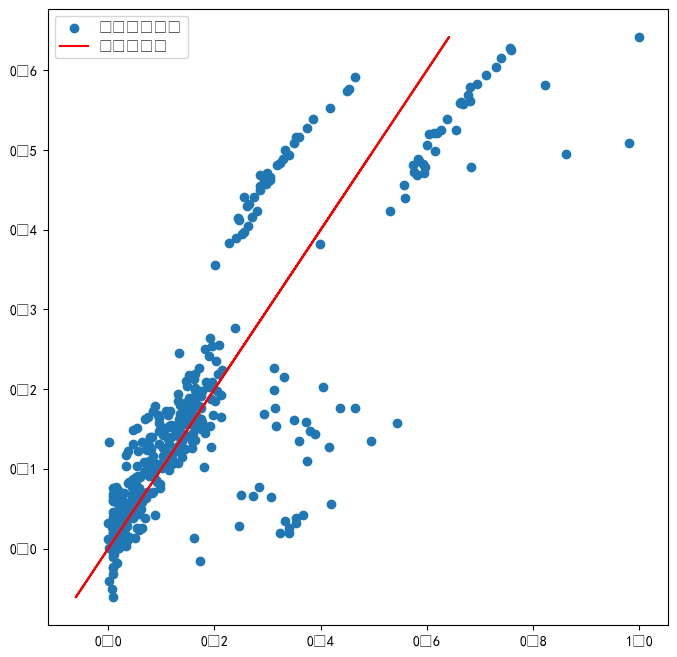

In [12]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'SimHei'
y_pred = model.predict(x_test)
plt.figure(figsize=(8,8))
plt.scatter(y_test,y_pred,label='测试集目标值')
plt.plot(y_pred,y_pred,'r',label='模型预测值')
plt.legend(loc='upper left')
plt.show()

In [14]:
df.loc[df['region']=='southwest','resign'] = 1
df.head()

,age,sex,bmi,children,smoker,region,charges,resign
0,19,0,27.900,0,1,1,16884.92400,NaN
1,18,1,33.770,1,0,2,1725.55230,NaN
2,28,1,33.000,3,0,2,4449.46200,NaN
3,33,1,22.705,0,0,3,21984.47061,NaN
4,32,1,28.880,0,0,3,3866.85520,NaN


In [15]:
df.insert(6,'bmisomker',df['smoker'] * (df['bmi']>=30).astype(int))
df.head()

,age,sex,bmi,children,smoker,region,bmisomker,charges,resign
0,19,0,27.900,0,1,1,0,16884.92400,NaN
1,18,1,33.770,1,0,2,0,1725.55230,NaN
2,28,1,33.000,3,0,2,0,4449.46200,NaN
3,33,1,22.705,0,0,3,0,21984.47061,NaN
4,32,1,28.880,0,0,3,0,3866.85520,NaN


In [ ]:
scaler = MinMaxScaler()
scaler.fit(df)
df1 = scaler.transform(df)
df1.min(),df1.max()

d:\Anaconda3\Lib\site-packages\sklearn\utils\_array_api.py:686: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
d:\Anaconda3\Lib\site-packages\sklearn\utils\_array_api.py:706: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


(np.float64(nan), np.float64(nan))